In [1]:
%load_ext autoreload
%autoreload 2

# SupCon learning

## build datasets

/home/hmack/projects/smartrodent_experiments/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


'len(dataset)=16981'

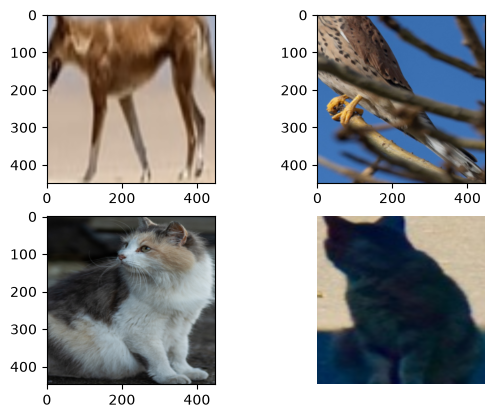

In [2]:
from pathlib import Path

from smartrodent.datasets import ImageDataset

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
if not (project_root / "pyproject.toml").exists():
    raise RuntimeError("Run this notebook from the repository root or notebooks directory")

import matplotlib.pyplot as plt
import numpy as np
import torch
from pytorch_metric_learning.samplers import MPerClassSampler
from torchvision.transforms.v2 import (
    Compose,
    InterpolationMode,
    PILToTensor,
    RandomAdjustSharpness,
    RandomGrayscale,
    RandomHorizontalFlip,
    RandomPerspective,
    RandomResizedCrop,
    Resize,
    ToDtype,
)

# params
size = 448
labels = sorted(
    [
    "Rattus rattus", # black rat
    "Rattus norvegicus", # brown rat
    "Bandicota bengalensis", # lesser bandicot rat
    "Bandicota indica", # greater bandicot rat
    "Mus booduga", # little indian field mouse
    "Mus musculus",
    "Vandeleuria oleraceus", # climbing mouse
    "Tatera indica", # indian gerbil
    "Suncus murinus", # shrew
    "Ptyas mucosa", # indian rat snake
    "Python molurus", # rock python
    "Naja naja", # indian cobra
    "Tyto javanica", # eastern barn owl
    "Ninox scutulata", # brown boobook
    "Glaucidium radiatum", # jungle owlet
    "Ketupa zeylonensis", # Brown fish owl
    "Ketupa nipalensis", # spot-bellied eagle-owl
    "Glaucidium castanotum", # chestnut-backed owlet
    "Otus thilohoffmanni", # some owl thing
    "Milvus migrans", # Black kite
    "Accipiter virgatus", # common kestrel
    "Falco tinnunculus", # besra
    "Urva edwardsii", # Indian grey mongoose
    "Felis catus", # house cat
    "Canis familiaris", # domestic dog
    ]
)
path = Path(
    project_root / "datasets/stage8_yolo_classifier_srilanka/train"
)
seed = 42
p = 4  # number of classes
m = 3  # number of examples

transform = Compose(
    [
        PILToTensor(),
        ToDtype(torch.float32, scale=True),
        Resize((size, size), antialias=True),
        RandomAdjustSharpness(sharpness_factor=0.7, p=0.2),
        RandomGrayscale(p=0.2),
        RandomPerspective(
            distortion_scale=0.2,
            p=0.2,
            interpolation=InterpolationMode.BILINEAR,
            fill=0,
        ),
        RandomHorizontalFlip(
            p=0.2,
        ),
        RandomResizedCrop(
            (size, size),
            scale=(0.7, 1.0),
            ratio=(3.0 / 4.0, 4.0 / 3.0),
            interpolation=InterpolationMode.BILINEAR,
            antialias=True,
        ),
    ]
)
dataset = ImageDataset(path, transform=transform, labels=labels, size=size)

# set numpy seed
np.random.seed(seed)

# make dataset
# check that images are loaded and augmented
display(f"len(dataset)={len(dataset)}")
fig, subplots = plt.subplots(2, 2)
lbl1, img1 = dataset[1278]
img1 = img1.detach().cpu().permute(1, 2, 0).numpy()

lbl2, img2 = dataset[2278]
img2 = img2.detach().cpu().permute(1, 2, 0).numpy()

lbl3, img3 = dataset[3278]
img3 = img3.detach().cpu().permute(1, 2, 0).numpy()

lbl4, img4 = dataset[4278]
img4 = img4.detach().cpu().permute(1, 2, 0).numpy()

subplots[0, 0].imshow(img1, label=lbl1)
subplots[0, 1].imshow(img2, label=lbl2)
subplots[1, 0].imshow(img3, label=lbl3)
subplots[1, 1].imshow(img4, label=lbl4)

plt.axis("off")
plt.show()


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.08286402..1.0000002].


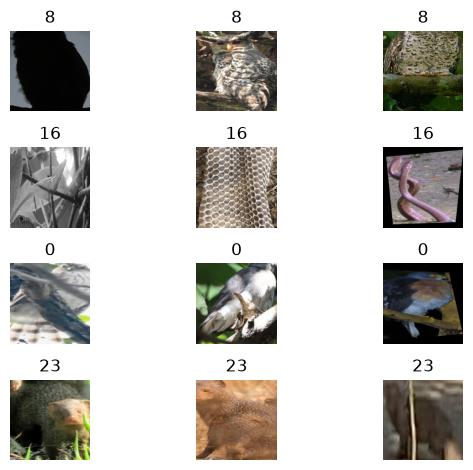

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torchvision.transforms.v2 import (
    Compose,
    InterpolationMode,
    PILToTensor,
    RandomAdjustSharpness,
    RandomGrayscale,
    RandomHorizontalFlip,
    RandomPerspective,
    RandomResizedCrop,
    Resize,
)

# make sampler and dataloader
sample_labels = [dataset.label_names[path.parent.name] for path in dataset.images]
sampler = MPerClassSampler(labels=sample_labels, m=m, batch_size=p * m)
transform = Compose(
    [
        PILToTensor(),
        ToDtype(torch.float32, scale=True),
        Resize((size, size), antialias=True),
        RandomAdjustSharpness(sharpness_factor=0.5, p=0.2),
        RandomGrayscale(p=0.2),
        RandomPerspective(
            distortion_scale=0.4,
            p=0.2,
            interpolation=InterpolationMode.BILINEAR,
            fill=0,
        ),
        RandomHorizontalFlip(
            p=0.2,
        ),
        RandomResizedCrop(
            (size, size),
            scale=(0.75, 1.0),
            ratio=(3.0 / 4.0, 4.0 / 3.0),
            interpolation=InterpolationMode.BILINEAR,
            antialias=True,
        ),
    ]
)
dataset = ImageDataset(path, transform=transform, labels=labels, size=size)

rng = torch.random.manual_seed(seed)
# Defining a custom data loader
dataloader = torch.utils.data.DataLoader(
    # Replace with the dataset object
    dataset=dataset,
    # Defining the batch size
    batch_size=p * m,
    # If true, shuffles the dataset at every epoch. Cannot be used with explicit sampler
    shuffle=False,
    # sampler to build the main issues.
    sampler=sampler,
    # Number of parallel processes for loading the data
    num_workers=0,
    # generator
    generator=rng,
    # multiprocessing context
    # multiprocessing_context="spawn"
    drop_last=True,
)

labelsstr, images = next(iter(dataloader))
fig, subplots = plt.subplots(p, m)
for lbl, img, ax in zip(labelsstr, images, subplots.flatten()):
    img = img.detach().cpu().permute(1, 2, 0).numpy()
    ax.imshow(img, label=lbl)
    ax.set_title(int(lbl))
    ax.axis("off")
fig.tight_layout()
fig.show()


## Model from ultralytics 

We need pooled, projected embeddings. loss is supplied by pytorch-metric learning

## Standalone training

Run from the repository root in the project environment:

```bash
python scripts/train_supcon.py configs/train_supcon_config.yaml
```

The configuration preserves the notebook's FP32, two-view experiment. Each epoch writes an architecture-and-weights checkpoint, optimizer state, class mapping, configuration, and scalar history under `runs/supcon_standalone_xl/`.

Checkpoints and evaluation can be used in a fresh notebook session without repeating training.


In [4]:
from smartrodent.supcon_model import YoloSupConModel

# Existing notebook experiment, preserved when moving training into the script.
# For a new script run, use runs/supcon_standalone_xl/epoch_0005.pt instead.
eval_trained_checkpoint = project_root / "runs/supcon_standalone_xl_srilanka_lr-000025/best.pt"
model = YoloSupConModel.from_checkpoint(eval_trained_checkpoint, device="cpu")
model.finalize()  # Evaluation uses its own temporary feature hook.

display(model.training_configuration)

size = model.training_configuration["transforms"]["image_size"]
seed = model.training_configuration["seed"]
labels = sorted(model.label_names)
path = Path(model.training_configuration["train_dataset"])
if not path.is_absolute():
    path = project_root / path
dataset = ImageDataset(path, labels=labels)
print("Loaded checkpoint:", eval_trained_checkpoint)


YOLO26x-cls summary: 176 layers, 29,637,064 parameters, 29,637,064 gradients


{'train_dataset': 'datasets/stage8_yolo_classifier_srilanka/train',
 'output_directory': 'runs/supcon_standalone_xl_srilanka',
 'class_names': ['Rattus rattus',
  'Bandicota bengalensis',
  'Bandicota indica',
  'Mus booduga',
  'Vandeleuria oleraceus',
  'Tatera indica',
  'Suncus murinus',
  'Ptyas mucosa',
  'Python molurus',
  'Naja naja',
  'Tyto javanica',
  'Ninox scutulata',
  'Glaucidium radiatum',
  'Ketupa zeylonensis',
  'Ketupa nipalensis',
  'Glaucidium castanotum',
  'Otus thilohoffmanni',
  'Milvus migrans',
  'Accipiter virgatus',
  'Falco tinnunculus',
  'Urva edwardsii',
  'Felis catus',
  'Canis familiaris'],
 'transforms': {'image_size': 448,
  'resize': {'interpolation': 'bilinear', 'antialias': True},
  'random_adjust_sharpness': {'sharpness_factor': 0.5, 'p': 0.2},
  'random_grayscale': {'p': 0.2},
  'random_perspective': {'distortion_scale': 0.5,
   'p': 0.2,
   'interpolation': 'bilinear',
   'fill': 0},
  'random_horizontal_flip': {'p': 0.2},
  'random_resize

Loaded checkpoint: /mnt/data/home/hmack/projects/smartrodent_experiments/runs/supcon_standalone_xl_srilanka_lr-000025/best.pt


## Eval

Compare the **same balanced subset of original images** through the pretrained encoder, trained encoder, and trained projector. Preprocessing is deterministic: RGB conversion, float scaling, and resizing, with no random augmentation.

Load the trained checkpoint in the cell above before running these cells. Extraction works after `model.finalize()` and temporarily disables dropout and BatchNorm updates, restoring their previous modes afterward. Feature arrays are copied to CPU.

The baseline checkpoint defaults to CPU so a second model is not allocated on the training GPU. The three t-SNE panels use separate fits and consistent species colors; their axes and inter-cluster positions are not a shared coordinate system. Labels are used for selection and coloring, not to fit t-SNE.


In [5]:
from collections import Counter

from ultralytics import YOLO
from smartrodent.datasets import ImageDataset

from smartrodent.eval import EvaluationImages, FeatureExtractor
# params
size = 448
path = Path(
    project_root / "datasets/stage8_yolo_classifier_srilanka/train"
)
seed = 42
transform = Compose(
    [
        PILToTensor(),
        ToDtype(torch.float32, scale=True),
        Resize((size, size), antialias=True),
        RandomAdjustSharpness(sharpness_factor=0.7, p=0.2),
        RandomGrayscale(p=0.2),
        RandomPerspective(
            distortion_scale=0.2,
            p=0.2,
            interpolation=InterpolationMode.BILINEAR,
            fill=0,
        ),
        RandomHorizontalFlip(
            p=0.2,
        ),
        RandomResizedCrop(
            (size, size),
            scale=(0.7, 1.0),
            ratio=(3.0 / 4.0, 4.0 / 3.0),
            interpolation=InterpolationMode.BILINEAR,
            antialias=True,
        ),
    ]
)
dataset = ImageDataset(path, transform=transform, labels=labels, size=size)

assert sorted(labels) == sorted(dataset.label_names)

# Explicitly cap the balanced subset at the least-populated species.
eval_class_counts = Counter(image.parent.name for image in dataset.images)
eval_samples_per_class = min(
    100, min(eval_class_counts[name] for name in dataset.label_names)
)
eval_images = EvaluationImages(
    images=dataset.images,
    label_names=dataset.label_names,
    samples_per_class=eval_samples_per_class,
    image_size=size,
    seed=seed,
)
eval_batch_size = 8
eval_workers = 0
eval_checkpoint = Path(model.training_configuration["model_name"])
if not eval_checkpoint.is_absolute():
    eval_checkpoint = project_root / eval_checkpoint
eval_baseline_device = "cpu"  # Set to "cuda" if you prefer after training.
eval_perplexity = min(30.0, len(eval_images) - 1)
print(
    f"Eval: {eval_samples_per_class} images per species, "
    f"{len(eval_images)} total; perplexity={eval_perplexity}"
)
print(dataset.label_names)
display(eval_checkpoint)

Eval: 16 images per species, 368 total; perplexity=30.0
{'Accipiter virgatus': 0, 'Bandicota bengalensis': 1, 'Bandicota indica': 2, 'Canis familiaris': 3, 'Falco tinnunculus': 4, 'Felis catus': 5, 'Glaucidium castanotum': 6, 'Glaucidium radiatum': 7, 'Ketupa nipalensis': 8, 'Ketupa zeylonensis': 9, 'Milvus migrans': 10, 'Mus booduga': 11, 'Naja naja': 12, 'Ninox scutulata': 13, 'Otus thilohoffmanni': 14, 'Ptyas mucosa': 15, 'Python molurus': 16, 'Rattus rattus': 17, 'Suncus murinus': 18, 'Tatera indica': 19, 'Tyto javanica': 20, 'Urva edwardsii': 21, 'Vandeleuria oleraceus': 22}


PosixPath('/mnt/data/home/hmack/projects/smartrodent_experiments/notebooks/yolo26x-cls.pt')

In [6]:
# Baseline: load the original weights, using precisely the same source images.
eval_baseline = YOLO(eval_checkpoint, task="classify")
try:
    eval_baseline.model.to(eval_baseline_device)
    baseline_features = FeatureExtractor(
        network=eval_baseline.model,
        pool=eval_baseline.model.model[-1].pool,
    ).extract(eval_images, batch_size=eval_batch_size, num_workers=eval_workers)
finally:
    del eval_baseline

print("Pretrained pooled:", baseline_features.pooled.shape)


Pretrained pooled: (368, 1280)


In [7]:
# Baseline: load the original weights, using precisely the same source images.
eval_checkpoint_classifier = "/home/hmack/projects/smartrodent_experiments/runs/classify/projects/training/classification/xl_speciesnames_448_reduced_augmentation/full_data_classifier_xl_speciesnames_448_reduced_augmentation/weights/best.pt"
eval_baseline_classifier = YOLO(eval_checkpoint_classifier, task="classify")
try:
    eval_baseline_classifier.model.to(eval_baseline_device)
    baseline_features_classifier = FeatureExtractor(
        network=eval_baseline_classifier.model,
        pool=eval_baseline_classifier.model.model[-1].pool,
    ).extract(eval_images, batch_size=eval_batch_size, num_workers=eval_workers)
finally:
    del eval_baseline_classifier

print("Pretrained classifier pooled:", baseline_features_classifier.pooled.shape)


Pretrained classifier pooled: (368, 1280)


In [8]:
# Use the trained weights already held in memory; do not reload the checkpoint.
trained_features = FeatureExtractor(
    network=model.full_model.model,
    pool=model.head.pool,
    projector=model.projector,
).extract(eval_images, batch_size=eval_batch_size, num_workers=eval_workers)

print("Trained pooled:", trained_features.pooled.shape)
print("Trained projected:", trained_features.projected.shape)


Trained pooled: (368, 1280)
Trained projected: (368, 128)


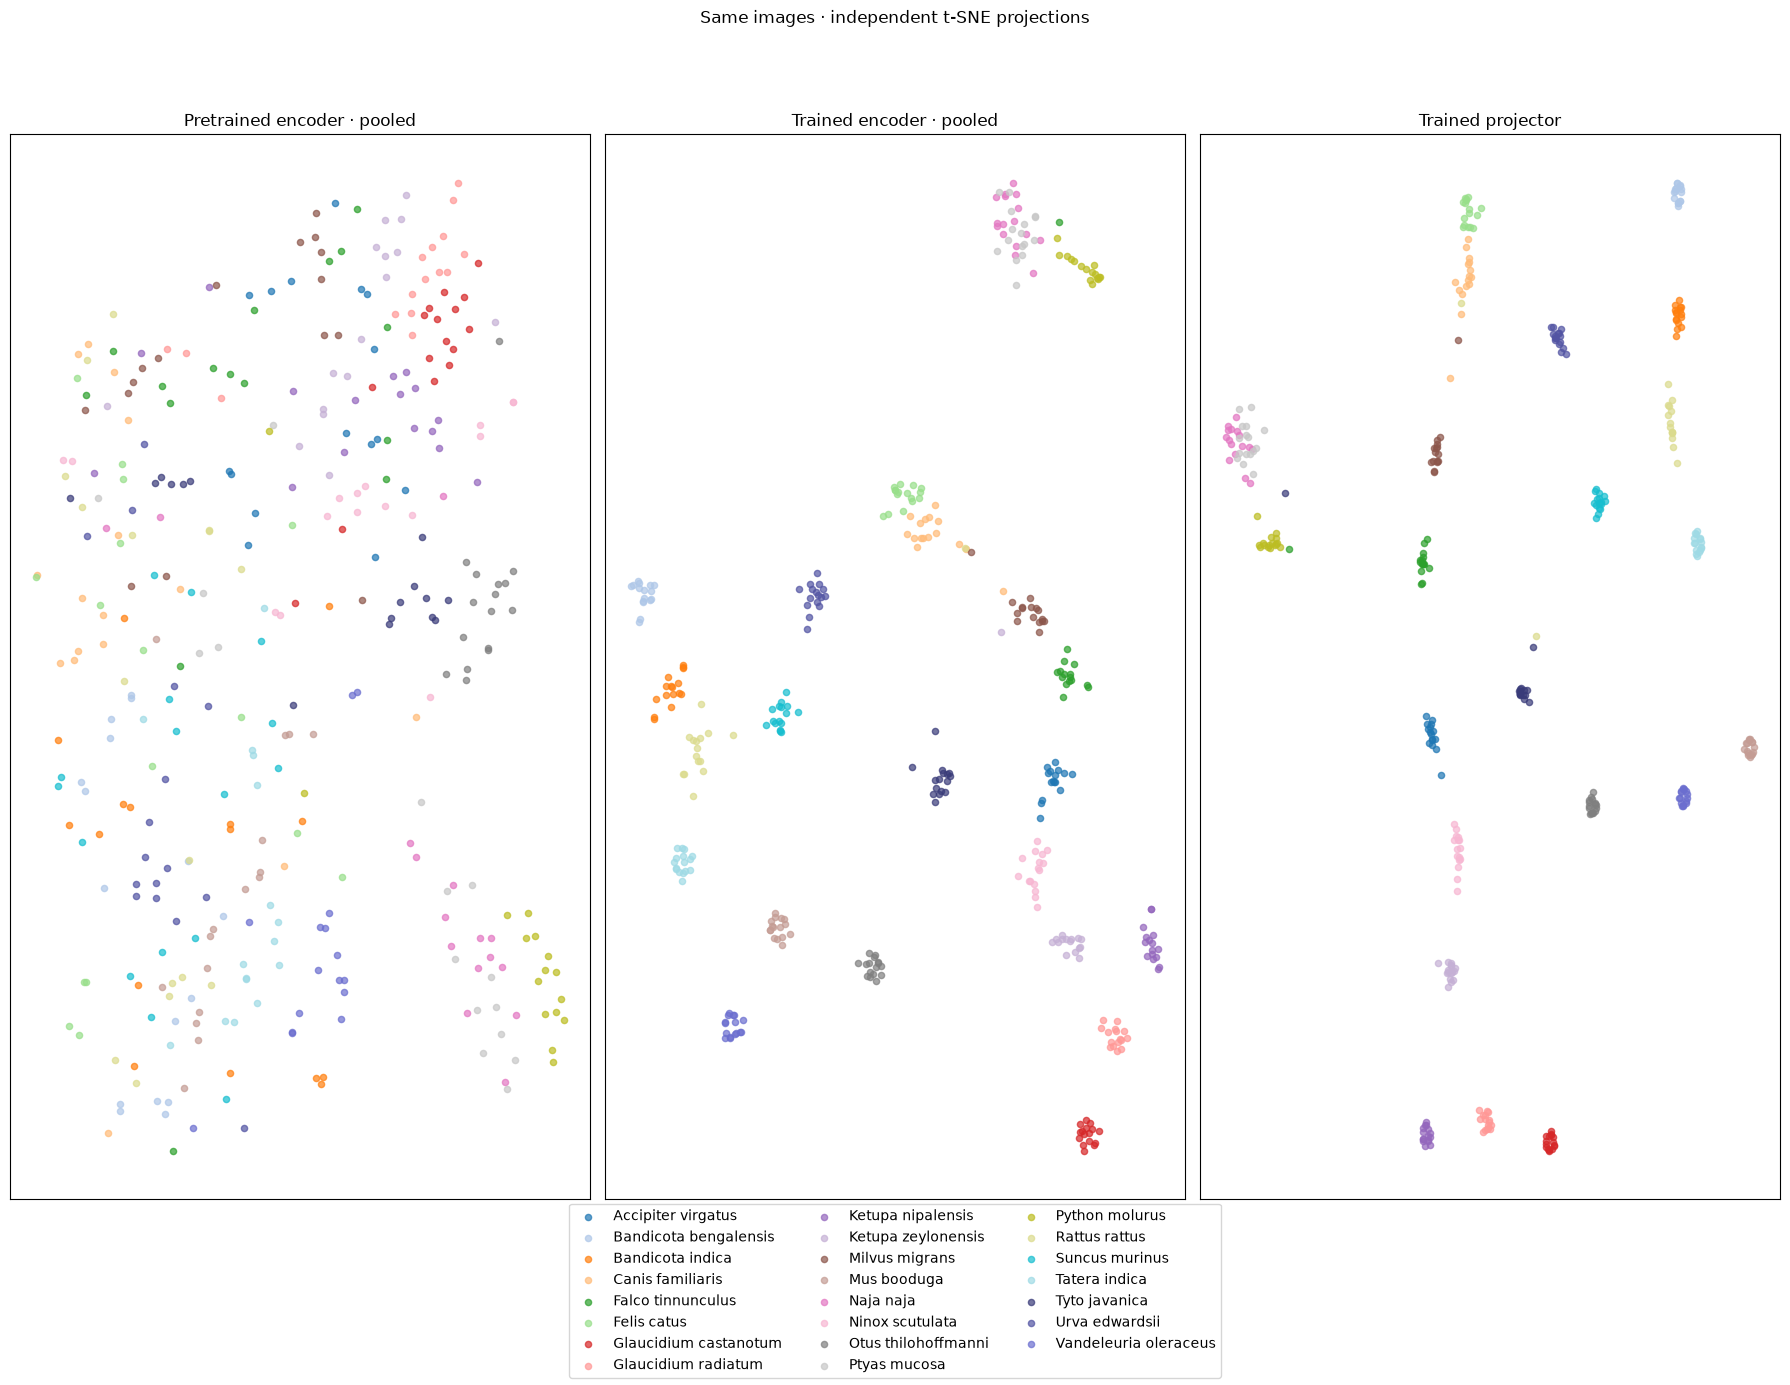

In [9]:
from smartrodent.eval import TsneComparison

eval_comparison = TsneComparison(
    perplexity=eval_perplexity,
    pca_components=None,
    seed=seed,
    max_iter=1000,
)

eval_figure, eval_coordinates = eval_comparison.plot(
    baseline=baseline_features,
    trained=trained_features,
    figsize=(18, 14),
    markersize= 20,
)

plt.show()

# Optional export, outside the image dataset:
eval_figure.savefig("eval_embeddings_full_sri_lanka_nopca.png", dpi=200, bbox_inches="tight")


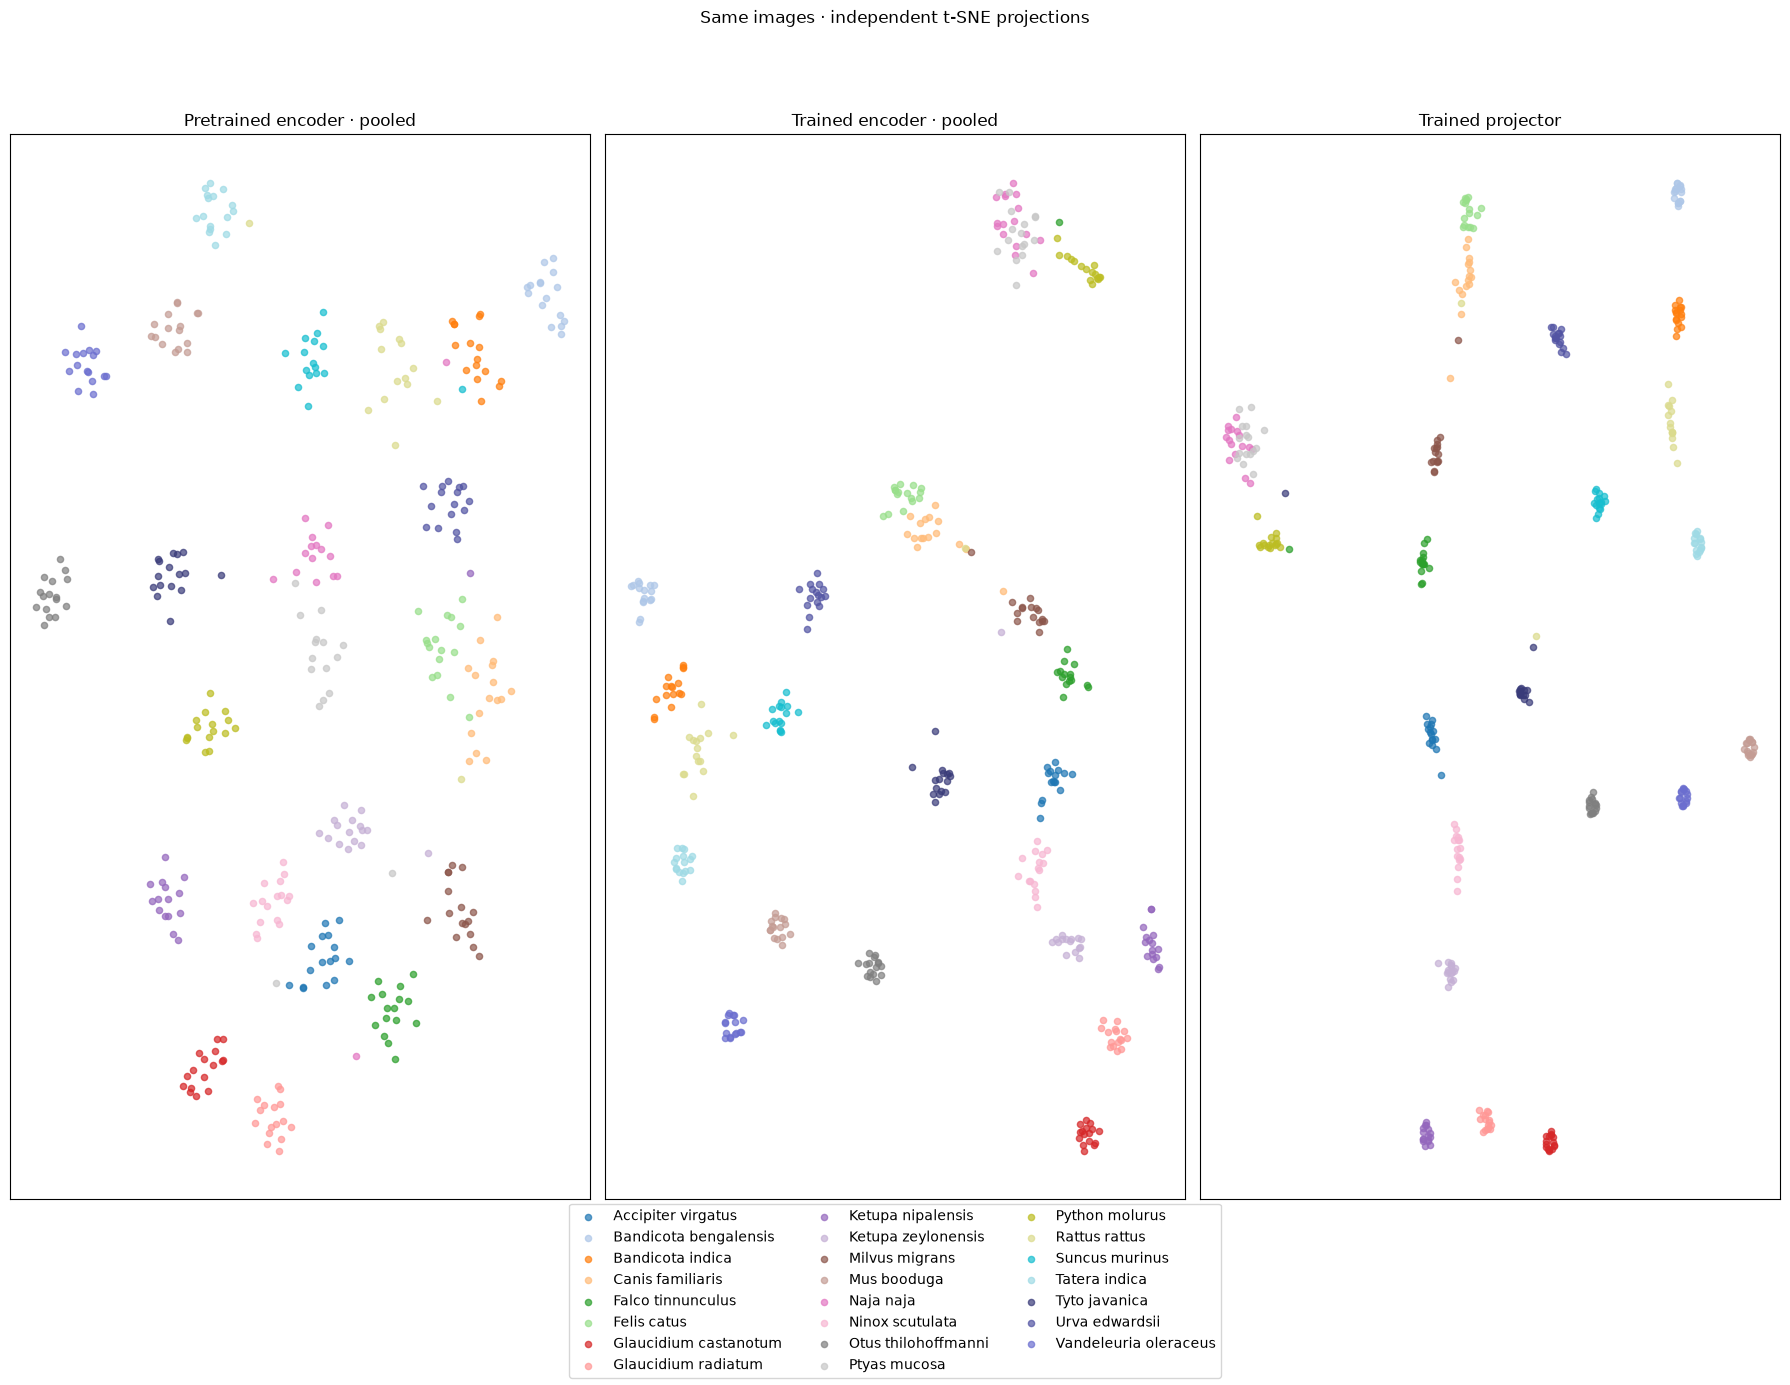

In [10]:
from smartrodent.eval import TsneComparison

eval_comparison = TsneComparison(
    perplexity=eval_perplexity,
    pca_components=None,
    seed=seed,
    max_iter=1000,
)

eval_figure, eval_coordinates = eval_comparison.plot(
    baseline=baseline_features_classifier,
    trained=trained_features,
    figsize=(18, 14),
    markersize= 20,
)

plt.show()

# Optional export, outside the image dataset:
eval_figure.savefig("eval_embeddings_full_sri_lanka_vs_classifier_nopca.png", dpi=200, bbox_inches="tight")


### Experiment observation

The first t-SNE inspection showed substantial overlap between **Rattus rattus** and **Rattus norvegicus** with the current augmentations. The other included species appeared better separated. This is a visual observation from this experiment, not a held-out classification result; revisit it when comparing augmentation settings and the pooled versus projected representations.


# kNN classifier on the embeddings for the test dataset

Fit a cosine-distance kNN classifier on **all** deterministic training embeddings, then evaluate it on the corresponding test split. The comparison covers the pretrained encoder, supervised classifier encoder, SupCon encoder, and SupCon projector.


In [13]:
from PIL import Image
from torch.utils.data import Dataset


class EmbeddingImageDataset(Dataset):
    """Load every labeled image in a split with deterministic preprocessing."""

    def __init__(self, root, label_names, image_size):
        self.root = Path(root)
        self.label_names = dict(label_names)
        extensions = {".jpg", ".jpeg", ".png"}
        self.images = tuple(
            sorted(
                image
                for name in self.label_names
                for image in (self.root / name).iterdir()
                if image.suffix.lower() in extensions
            )
        )
        self.transform = Compose(
            [
                PILToTensor(),
                ToDtype(torch.float32, scale=True),
                Resize((image_size, image_size), antialias=True),
            ]
        )

    def __len__(self):
        """Return the number of images in the split."""
        return len(self.images)

    def __getitem__(self, index):
        """Return the class ID and preprocessed RGB image."""
        image_path = self.images[index]
        with Image.open(image_path) as image:
            tensor = self.transform(image.convert("RGB"))
        return self.label_names[image_path.parent.name], tensor


knn_train_path = Path(model.training_configuration["train_dataset"])
if not knn_train_path.is_absolute():
    knn_train_path = project_root / knn_train_path
knn_test_path = knn_train_path.parent / "test"
if not knn_test_path.is_dir():
    raise FileNotFoundError(f"Expected test split at {knn_test_path}")

# Keep evaluation aligned with the classes and IDs stored in the SupCon checkpoint.
knn_label_names = dict(model.label_names)
knn_train_dataset = EmbeddingImageDataset(knn_train_path, knn_label_names, size)
knn_test_dataset = EmbeddingImageDataset(knn_test_path, knn_label_names, size)
knn_batch_size = 8
knn_workers = 0
knn_device = "cuda" if torch.cuda.is_available() else "cpu"
assert len(knn_train_dataset) > 0 and len(knn_test_dataset) > 0
print(f"Train: {len(knn_train_dataset):,}; test: {len(knn_test_dataset):,}; device: {knn_device}")


Train: 14,885; test: 3,196; device: cuda


In [16]:
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    top_k_accuracy_score,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import label_binarize, normalize


def evaluate_knn(name, train_embeddings, train_labels, test_embeddings, test_labels, normalize_cm:str = "all", n_neighbors:int=5):
    """Fit kNN and return requested test metrics and its confusion matrix."""
    # Normalize explicitly so changing the distance metric later cannot make
    # embedding magnitude an accidental part of the comparison.
    train_embeddings = normalize(train_embeddings, norm="l2")
    test_embeddings = normalize(test_embeddings, norm="l2")
    classifier = KNeighborsClassifier(
        n_neighbors=n_neighbors, metric="cosine", weights="distance", n_jobs=-1
    )
    classifier.fit(train_embeddings, train_labels)
    predictions = classifier.predict(test_embeddings)
    probabilities = classifier.predict_proba(test_embeddings)
    class_ids = np.array(sorted(knn_label_names.values()))
    if not np.array_equal(classifier.classes_, class_ids):
        raise ValueError(f"{name}: training split does not contain every class")

    binary_targets = label_binarize(test_labels, classes=class_ids)
    metrics = {
        "embedding": name,
        "f1_macro": f1_score(test_labels, predictions, average="macro"),
        "f1_micro": f1_score(test_labels, predictions, average="micro"),
        "roc_auc_macro": roc_auc_score(binary_targets, probabilities, average="macro"),
        "roc_auc_micro": roc_auc_score(binary_targets, probabilities, average="micro"),
        "recall_macro": recall_score(test_labels, predictions, average="macro", zero_division=0),
        "recall_micro": recall_score(test_labels, predictions, average="micro", zero_division=0),
        "precision_macro": precision_score(test_labels, predictions, average="macro", zero_division=0),
        "precision_micro": precision_score(test_labels, predictions, average="micro", zero_division=0),
        "top1_accuracy": accuracy_score(test_labels, predictions),
        "top5_accuracy": top_k_accuracy_score(
            test_labels, probabilities, k=min(5, len(class_ids)), labels=class_ids
        ),
    }
    matrix = confusion_matrix(test_labels, predictions, labels=class_ids, normalize=normalize_cm)
    return metrics, matrix


def extract_yolo_split_features(checkpoint):
    """Extract pooled train and test features from a YOLO checkpoint."""
    yolo = YOLO(checkpoint, task="classify")
    try:
        yolo.model.to(knn_device)
        extractor = FeatureExtractor(yolo.model, yolo.model.model[-1].pool)
        train_features = extractor.extract(
            knn_train_dataset, batch_size=knn_batch_size, num_workers=knn_workers
        )
        test_features = extractor.extract(
            knn_test_dataset, batch_size=knn_batch_size, num_workers=knn_workers
        )
    finally:
        del yolo
    return train_features, test_features


In [17]:
knn_results = []
knn_confusion_matrices = {}

# Evaluate the two YOLO encoder checkpoints one at a time to limit memory use.
yolo_embedding_checkpoints = {
    "Pretrained encoder (pooled)": eval_checkpoint,
    "Supervised classifier (pooled)": eval_checkpoint_classifier,
}
for embedding_name, checkpoint in yolo_embedding_checkpoints.items():
    print(f"Extracting {embedding_name} ...")
    train_features, test_features = extract_yolo_split_features(checkpoint)
    result, matrix = evaluate_knn(
        embedding_name,
        train_features.pooled,
        train_features.labels,
        test_features.pooled,
        test_features.labels,
        n_neighbors=10,
        normalize_cm=None
    )
    knn_results.append(result)
    knn_confusion_matrices[embedding_name] = matrix
    del train_features, test_features


Extracting Pretrained encoder (pooled) ...
Extracting Supervised classifier (pooled) ...


In [18]:
# One SupCon pass supplies both pooled and projected representations.
model.full_model.model.to(knn_device)
model.projector.to(knn_device)
supcon_extractor = FeatureExtractor(
    network=model.full_model.model, pool=model.head.pool, projector=model.projector
)
supcon_train = supcon_extractor.extract(
    knn_train_dataset, batch_size=knn_batch_size, num_workers=knn_workers
)
supcon_test = supcon_extractor.extract(
    knn_test_dataset, batch_size=knn_batch_size, num_workers=knn_workers
)

supcon_spaces = {
    "SupCon encoder (pooled)": (supcon_train.pooled, supcon_test.pooled),
    "SupCon projector": (supcon_train.projected, supcon_test.projected),
}
for embedding_name, (train_embeddings, test_embeddings) in supcon_spaces.items():
    result, matrix = evaluate_knn(
        embedding_name,
        train_embeddings,
        supcon_train.labels,
        test_embeddings,
        supcon_test.labels,
    )
    knn_results.append(result)
    knn_confusion_matrices[embedding_name] = matrix

knn_metrics = pd.DataFrame(knn_results).set_index("embedding")
knn_metrics.to_csv("/home/hmack/projects/smartrodent_experiments/notebooks/knn_results.csv")
display(knn_metrics.round(4))


,f1_macro,f1_micro,roc_auc_macro,roc_auc_micro,recall_macro,recall_micro,precision_macro,precision_micro,top1_accuracy,top5_accuracy
embedding,,,,,,,,,,
Pretrained encoder (pooled),0.5688,0.7606,0.8715,0.9594,0.5582,0.7606,0.5900,0.7606,0.7606,0.9324
Supervised classifier (pooled),0.7251,0.8658,0.8998,0.9678,0.7157,0.8658,0.7386,0.8658,0.8658,0.9459
SupCon encoder (pooled),0.7396,0.8814,0.8807,0.9644,0.7252,0.8814,0.7644,0.8814,0.8814,0.9421
SupCon projector,0.7230,0.8723,0.8688,0.9603,0.7021,0.8723,0.7822,0.8723,0.8723,0.9334


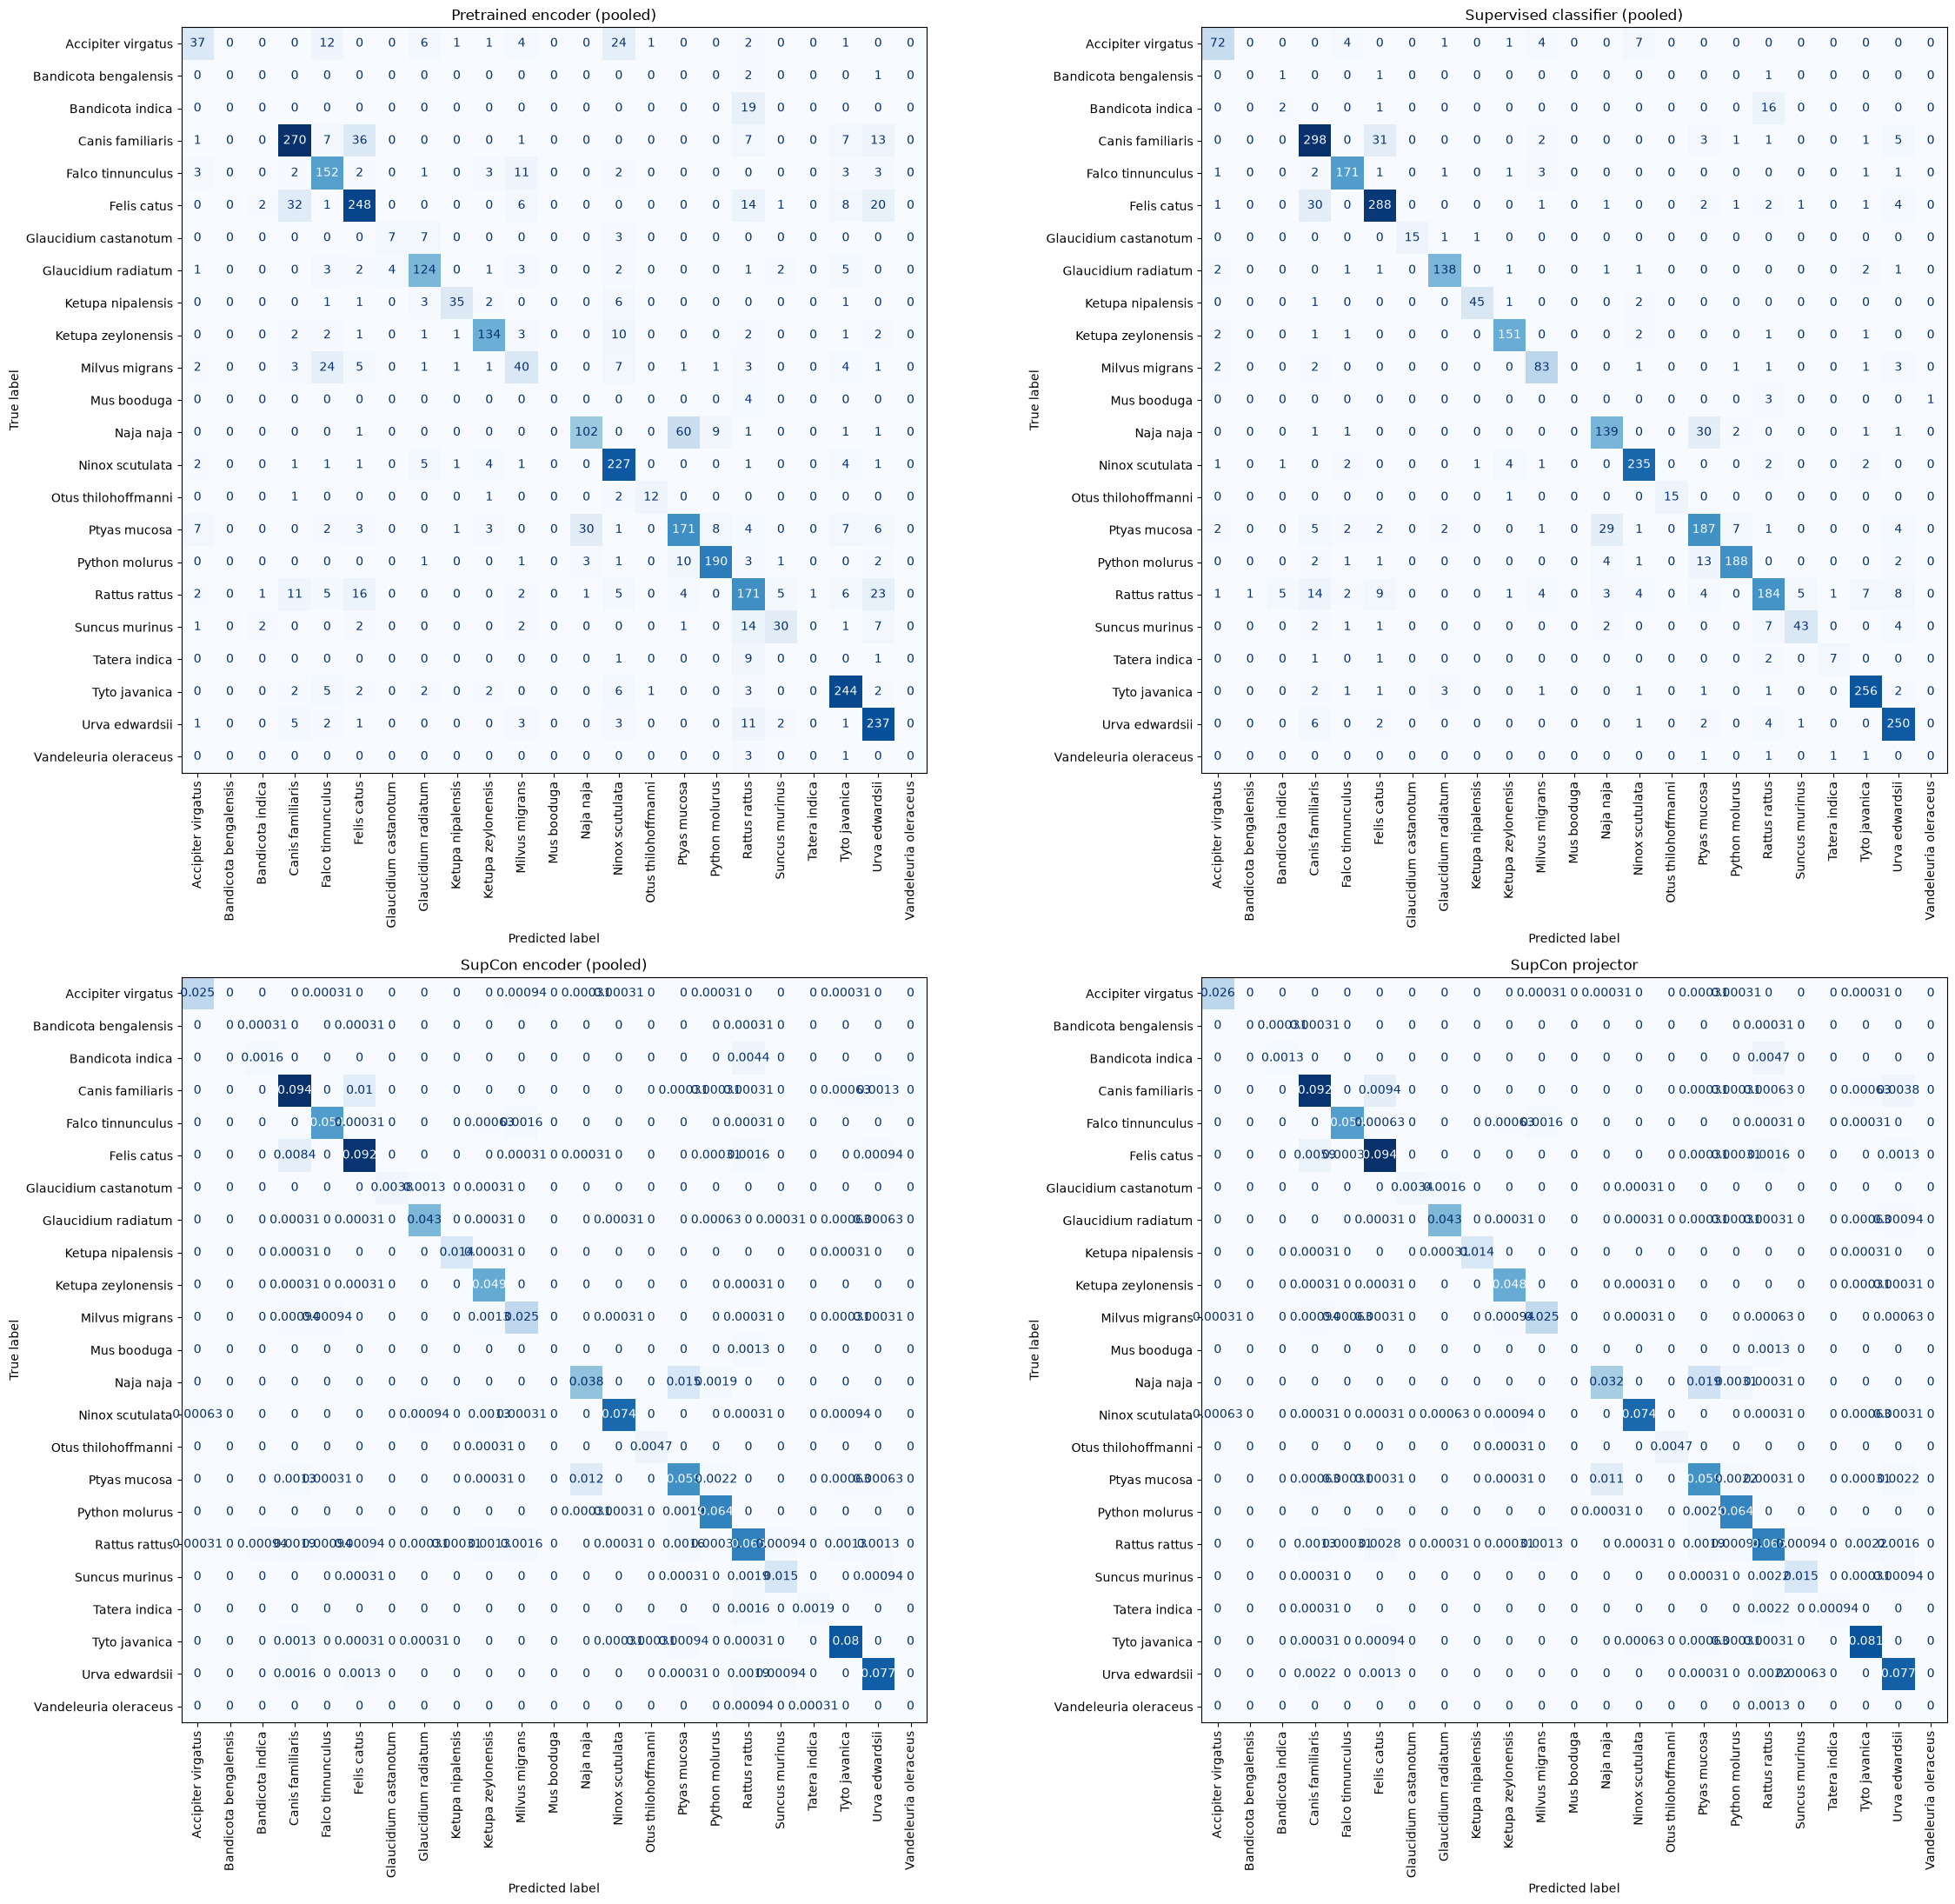

In [19]:
class_names = [
    name for name, class_id in sorted(knn_label_names.items(), key=lambda item: item[1])
]
figure, axes = plt.subplots(2, 2, figsize=(24, 22))
for axis, (embedding_name, matrix) in zip(axes.flat, knn_confusion_matrices.items()):
    ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(
        ax=axis, cmap="Blues", colorbar=False, xticks_rotation=90
    )
    axis.set_title(embedding_name)
figure.tight_layout()
plt.show()

figure.savefig("/home/hmack/projects/smartrodent_experiments/notebooks/knn_confusion_matrix.jpg")
